,A,B,C,D,E,F,G,H,I,J
A,0.00,52.61,35.61,35.36,72.80,57.97,80.80,72.03,71.59,88.02
B,52.61,0.00,27.78,63.07,36.50,60.61,57.14,83.74,19.31,76.66
C,35.61,27.78,0.00,35.47,37.20,36.40,47.42,58.31,42.58,60.13
D,35.36,63.07,35.47,0.00,63.64,29.00,60.90,37.12,77.62,59.82
E,72.80,36.50,37.20,63.64,0.00,44.64,23.26,66.21,31.38,46.04
F,57.97,60.61,36.40,29.00,44.64,0.00,34.21,23.35,68.60,31.06
G,80.80,57.14,47.42,60.90,23.26,34.21,0.00,50.49,54.63,23.35
H,72.03,83.74,58.31,37.12,66.21,23.35,50.49,0.00,91.83,35.44
I,71.59,19.31,42.58,77.62,31.38,68.60,54.63,91.83,0.00,77.03
J,88.02,76.66,60.13,59.82,46.04,31.06,23.35,35.44,77.03,0.00


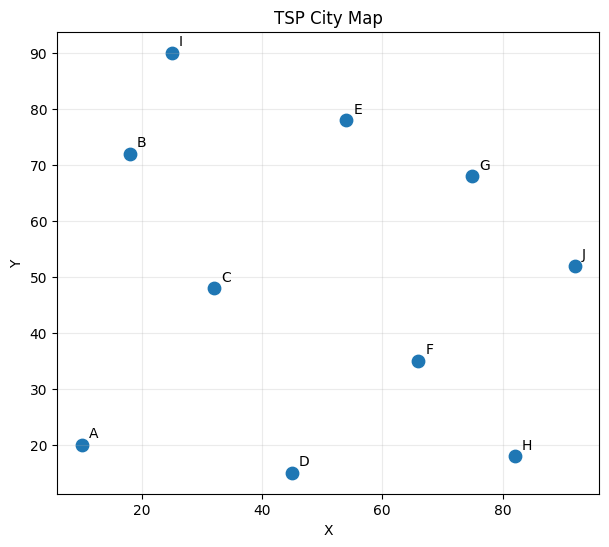

In [ ]:
import heapq, math, random, time, tracemalloc
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from itertools import permutations
from collections import deque

SEED = 42
random.seed(SEED)
np.random.seed(SEED)

CITY_NAMES = list("ABCDEFGH")
COORDS = {
    "A": (10, 20), "B": (18, 72), "C": (32, 48), "D": (45, 15), "E": (54, 78),
    "F": (66, 35), "G": (75, 68), "H": (82, 18), "I": (25, 90), "J": (92, 52)
}

def build_distance_matrix(cities):
    n = len(cities)
    d = np.zeros((n, n), dtype=float)
    for i in range(n):
        for j in range(n):
            if i != j:
                x1, y1 = COORDS[cities[i]]
                x2, y2 = COORDS[cities[j]]
                d[i, j] = round(math.hypot(x1 - x2, y1 - y2), 2)
    return d

DIST = build_distance_matrix(CITY_NAMES)

def tour_cost(route, dist=DIST):
    if not route:
        return 0.0
    return float(sum(dist[route[i], route[(i + 1) % len(route)]] for i in range(len(route))))

def route_text(route, cities=CITY_NAMES):
    return " -> ".join(cities[i] for i in route + [route[0]])

def show_problem():
    df = pd.DataFrame(DIST, index=CITY_NAMES, columns=CITY_NAMES)
    display(df)
    plt.figure(figsize=(7, 6))
    xs = [COORDS[c][0] for c in CITY_NAMES]
    ys = [COORDS[c][1] for c in CITY_NAMES]
    plt.scatter(xs, ys, s=80)
    for c, (x, y) in COORDS.items():
        plt.annotate(c, (x, y), xytext=(5, 5), textcoords="offset points")
    plt.title("TSP City Map")
    plt.xlabel("X")
    plt.ylabel("Y")
    plt.grid(alpha=0.25)
    plt.show()

show_problem()

In [ ]:
def bfs_tsp(dist, start=0):
    n = len(dist)
    q = deque([(start, (start,), 0.0)])
    expanded = 0
    best_route, best_cost = None, float("inf")
    while q:
        current, path, cost = q.popleft()
        expanded += 1
        if len(path) == n:
            total = cost + dist[current, start]
            if total < best_cost:
                best_cost, best_route = total, list(path)
            continue
        for nxt in range(n):
            if nxt not in path:
                q.append((nxt, path + (nxt,), cost + dist[current, nxt]))
    return best_route, best_cost, expanded

def dfs_tsp(dist, start=0):
    n = len(dist)
    best_route, best_cost = None, float("inf")
    expanded = 0
    stack = [(start, (start,), 0.0)]
    while stack:
        current, path, cost = stack.pop()
        expanded += 1
        if len(path) == n:
            total = cost + dist[current, start]
            if total < best_cost:
                best_cost, best_route = total, list(path)
            continue
        for nxt in reversed(range(n)):
            if nxt not in path:
                stack.append((nxt, path + (nxt,), cost + dist[current, nxt]))
    return best_route, best_cost, expanded

def ucs_tsp(dist, start=0):
    n = len(dist)
    pq = [(0.0, start, (start,))]
    expanded = 0
    best_full = float("inf")
    best_route = None
    while pq:
        cost, current, path = heapq.heappop(pq)
        expanded += 1
        if len(path) == n:
            total = cost + dist[current, start]
            if total < best_full:
                best_full, best_route = total, list(path)
            continue
        for nxt in range(n):
            if nxt not in path:
                heapq.heappush(pq, (cost + dist[current, nxt], nxt, path + (nxt,)))
    return best_route, best_full, expanded

In [ ]:
def mst_cost(nodes, dist):
    nodes = list(nodes)
    if len(nodes) <= 1:
        return 0.0
    in_tree = {nodes[0]}
    total = 0.0
    while len(in_tree) < len(nodes):
        best = float("inf")
        pick = None
        for u in in_tree:
            for v in nodes:
                if v not in in_tree and dist[u, v] < best:
                    best = dist[u, v]
                    pick = v
        total += best
        in_tree.add(pick)
    return total

def tsp_lower_bound(current, unvisited, start, dist):
    unvisited = set(unvisited)
    if not unvisited:
        return dist[current, start]
    mst = mst_cost(unvisited, dist)
    to_unvisited = min(dist[current, u] for u in unvisited)
    to_start = min(dist[u, start] for u in unvisited)
    return mst + to_unvisited + to_start

def greedy_tsp(dist, start=0):
    n = len(dist)
    pq = []
    h0 = tsp_lower_bound(start, range(1, n), start, dist)
    heapq.heappush(pq, (h0, start, (start,), 0.0))
    expanded = 0
    while pq:
        _, current, path, g = heapq.heappop(pq)
        expanded += 1
        if len(path) == n:
            return list(path), g + dist[current, start], expanded
        unvisited = [x for x in range(n) if x not in path]
        for nxt in unvisited:
            new_path = path + (nxt,)
            rem = [x for x in range(n) if x not in new_path]
            h = tsp_lower_bound(nxt, rem, start, dist)
            heapq.heappush(pq, (h, nxt, new_path, g + dist[current, nxt]))
    return None, float("inf"), expanded

def astar_tsp(dist, start=0):
    n = len(dist)
    pq = []
    h0 = tsp_lower_bound(start, range(1, n), start, dist)
    heapq.heappush(pq, (h0, 0.0, start, (start,)))
    expanded = 0
    while pq:
        f, g, current, path = heapq.heappop(pq)
        expanded += 1
        if len(path) == n:
            return list(path), g + dist[current, start], expanded
        for nxt in range(n):
            if nxt not in path:
                new_g = g + dist[current, nxt]
                new_path = path + (nxt,)
                rem = [x for x in range(n) if x not in new_path]
                h = tsp_lower_bound(nxt, rem, start, dist)
                heapq.heappush(pq, (new_g + h, new_g, nxt, new_path))
    return None, float("inf"), expanded

In [ ]:
def hill_climbing_tsp(dist, start=0, restarts=30, max_iter=1000):
    n = len(dist)
    best_global_route, best_global_cost = None, float("inf")
    total_iterations = 0
    successful_restarts = 0

    base = list(range(n))
    base.remove(start)

    for _ in range(restarts):
        current = [start] + random.sample(base, len(base))
        current_cost = tour_cost(current, dist)
        improved = False

        for _ in range(max_iter):
            total_iterations += 1
            best_neighbor = current
            best_neighbor_cost = current_cost

            for i in range(1, n - 1):
                for j in range(i + 1, n):
                    neighbor = current[:]
                    neighbor[i], neighbor[j] = neighbor[j], neighbor[i]
                    c = tour_cost(neighbor, dist)
                    if c < best_neighbor_cost:
                        best_neighbor, best_neighbor_cost = neighbor, c

            if best_neighbor_cost >= current_cost:
                break

            current, current_cost = best_neighbor, best_neighbor_cost
            improved = True

        if improved:
            successful_restarts += 1
        if current_cost < best_global_cost:
            best_global_route, best_global_cost = current[:], current_cost

    return best_global_route, best_global_cost, total_iterations, successful_restarts

def genetic_algorithm_tsp(dist, start=0, population_size=80, generations=300, mutation_rate=0.08, elite_size=4):
    n = len(dist)
    base = list(range(n))
    base.remove(start)

    def make_route():
        return [start] + random.sample(base, len(base))

    def fitness(route):
        return 1.0 / (tour_cost(route, dist) + 1e-12)

    def selection(pop, fits):
        elite_idx = np.argsort(fits)[-elite_size:][::-1]
        elites = [pop[i][:] for i in elite_idx]
        weights = np.array(fits) / np.sum(fits)
        idx = np.random.choice(len(pop), size=len(pop) - elite_size, p=weights)
        return elites + [pop[i][:] for i in idx]

    def ox(parent1, parent2):
        child = [None] * n
        child[0] = start
        a, b = sorted(random.sample(range(1, n), 2))
        child[a:b] = parent1[a:b]
        used = set(x for x in child if x is not None)
        fill = [x for x in parent2 if x not in used]
        k = 0
        for i in list(range(1, a)) + list(range(b, n)):
            child[i] = fill[k]
            k += 1
        return child

    def mutate(route):
        if random.random() < mutation_rate:
            i, j = random.sample(range(1, n), 2)
            route[i], route[j] = route[j], route[i]

    population = [make_route() for _ in range(population_size)]
    best_route = min(population, key=lambda r: tour_cost(r, dist))
    best_cost = tour_cost(best_route, dist)
    history = [best_cost]

    for _ in range(generations):
        fits = [fitness(r) for r in population]
        selected = selection(population, fits)
        new_pop = selected[:elite_size]

        while len(new_pop) < population_size:
            p1, p2 = random.sample(selected, 2)
            child = ox(p1, p2)
            mutate(child)
            new_pop.append(child)

        population = new_pop
        current_best = min(population, key=lambda r: tour_cost(r, dist))
        current_cost = tour_cost(current_best, dist)
        if current_cost < best_cost:
            best_route, best_cost = current_best[:], current_cost
        history.append(best_cost)

    return best_route, best_cost, generations, history

In [ ]:
def backtracking_csp(dist, start=0):
    n = len(dist)
    best_route = None
    best_cost = float("inf")
    expanded = 0

    def search(path, remaining, cost):
        nonlocal best_route, best_cost, expanded
        expanded += 1
        if not remaining:
            total = cost + dist[path[-1], start]
            if total < best_cost:
                best_cost = total
                best_route = path[:]
            return
        for nxt in sorted(remaining, key=lambda x: dist[path[-1], x]):
            new_cost = cost + dist[path[-1], nxt]
            if new_cost < best_cost:
                search(path + [nxt], remaining - {nxt}, new_cost)

    search([start], set(range(n)) - {start}, 0.0)
    return best_route, best_cost, expanded

def branch_and_bound_tsp(dist, start=0):
    n = len(dist)
    best_route = None
    best_cost = float("inf")
    expanded = 0

    def search(path, remaining, cost):
        nonlocal best_route, best_cost, expanded
        expanded += 1

        if not remaining:
            total = cost + dist[path[-1], start]
            if total < best_cost:
                best_cost = total
                best_route = path[:]
            return

        lb = cost + tsp_lower_bound(path[-1], remaining, start, dist)
        if lb >= best_cost:
            return

        candidates = sorted(remaining, key=lambda x: dist[path[-1], x])
        for nxt in candidates:
            new_cost = cost + dist[path[-1], nxt]
            if new_cost < best_cost:
                search(path + [nxt], remaining - {nxt}, new_cost)

    search([start], set(range(n)) - {start}, 0.0)
    return best_route, best_cost, expanded

In [ ]:
def exhaustive_optimal_tsp(dist, start=0):
    n = len(dist)
    best_route, best_cost = None, float("inf")
    expanded = 0
    others = [x for x in range(n) if x != start]
    for perm in permutations(others):
        expanded += 1
        route = [start] + list(perm)
        c = tour_cost(route, dist)
        if c < best_cost:
            best_route, best_cost = route, c
    return best_route, best_cost, expanded

def run_one(name, fn):
    tracemalloc.start()
    t0 = time.perf_counter()
    out = fn()
    elapsed = time.perf_counter() - t0
    _, peak = tracemalloc.get_traced_memory()
    tracemalloc.stop()
    return out, elapsed, peak / (1024**2)

results = []

def add_result(name, route, cost, elapsed, memory_mb, expanded=None, iterations=None, generations=None, success=None):
    results.append({
        "Algorithm": name,
        "Route": route_text(route) if route else None,
        "Distance": round(cost, 2),
        "Time (s)": elapsed,
        "Peak Memory (MB)": round(memory_mb, 3),
        "States Expanded": expanded,
        "Iterations": iterations,
        "Generations": generations,
        "Success / Restarts": success
    })

algorithms = [
    ("BFS", lambda: bfs_tsp(DIST)),
    ("DFS", lambda: dfs_tsp(DIST)),
    ("Uniform Cost Search", lambda: ucs_tsp(DIST)),
    ("Greedy Best-First", lambda: greedy_tsp(DIST)),
    ("A*", lambda: astar_tsp(DIST)),
]

for name, fn in algorithms:
    (route, cost, expanded), elapsed, mem = run_one(name, fn)
    add_result(name, route, cost, elapsed, mem, expanded=expanded)

(route, cost, iters, success), elapsed, mem = run_one(
    "Hill Climbing",
    lambda: hill_climbing_tsp(DIST, restarts=30, max_iter=1000)
)
add_result("Hill Climbing", route, cost, elapsed, mem, iterations=iters, success=success)

(route, cost, gens, history), elapsed, mem = run_one(
    "Genetic Algorithm",
    lambda: genetic_algorithm_tsp(DIST, population_size=80, generations=300, mutation_rate=0.08)
)
add_result("Genetic Algorithm", route, cost, elapsed, mem, generations=gens)

(route, cost, expanded), elapsed, mem = run_one(
    "CSP Backtracking + Pruning",
    lambda: backtracking_csp(DIST)
)
add_result("CSP Backtracking + Pruning", route, cost, elapsed, mem, expanded=expanded)

(route, cost, expanded), elapsed, mem = run_one(
    "CSP Branch & Bound",
    lambda: branch_and_bound_tsp(DIST)
)
add_result("CSP Branch & Bound", route, cost, elapsed, mem, expanded=expanded)

opt_route, opt_cost, opt_expanded = exhaustive_optimal_tsp(DIST)
results_df = pd.DataFrame(results)
results_df["Optimality Gap (%)"] = ((results_df["Distance"] - opt_cost) / opt_cost * 100).round(3)
results_df = results_df.sort_values("Distance").reset_index(drop=True)

print("Optimal route:", route_text(opt_route))
print("Optimal distance:", round(opt_cost, 2))
display(results_df)

Optimal route: A -> C -> B -> I -> E -> G -> J -> H -> F -> D -> A
Optimal distance: 283.84


,Algorithm,Route,Distance,Time (s),Peak Memory (MB),States Expanded,Iterations,Generations,Success / Restarts,Optimality Gap (%)
0,BFS,A -> C -> B -> I -> E -> G -> J -> H -> F -> D...,283.84,5.040561,75.787,986410.0,NaN,NaN,NaN,0.000
1,DFS,A -> C -> B -> I -> E -> G -> J -> H -> F -> D...,283.84,3.411640,0.003,986410.0,NaN,NaN,NaN,0.000
2,Uniform Cost Search,A -> D -> F -> H -> J -> G -> E -> I -> B -> C...,283.84,9.307614,55.848,986410.0,NaN,NaN,NaN,0.000
3,A*,A -> D -> F -> H -> J -> G -> E -> I -> B -> C...,283.84,0.005053,0.008,16.0,NaN,NaN,NaN,0.000
4,Genetic Algorithm,A -> D -> F -> H -> J -> G -> E -> I -> B -> C...,283.84,1.349397,0.064,NaN,NaN,300.0,NaN,0.000
5,Hill Climbing,A -> C -> B -> I -> E -> G -> J -> H -> F -> D...,283.84,0.084207,0.002,NaN,177.0,NaN,30.0,0.000
6,CSP Backtracking + Pruning,A -> D -> F -> H -> J -> G -> E -> I -> B -> C...,283.84,0.432565,0.007,43197.0,NaN,NaN,NaN,0.000
7,CSP Branch & Bound,A -> D -> F -> H -> J -> G -> E -> I -> B -> C...,283.84,0.005143,0.008,79.0,NaN,NaN,NaN,0.000
8,Greedy Best-First,A -> C -> B -> H -> I -> E -> G -> J -> F -> D...,412.37,0.003547,0.009,10.0,NaN,NaN,NaN,45.283


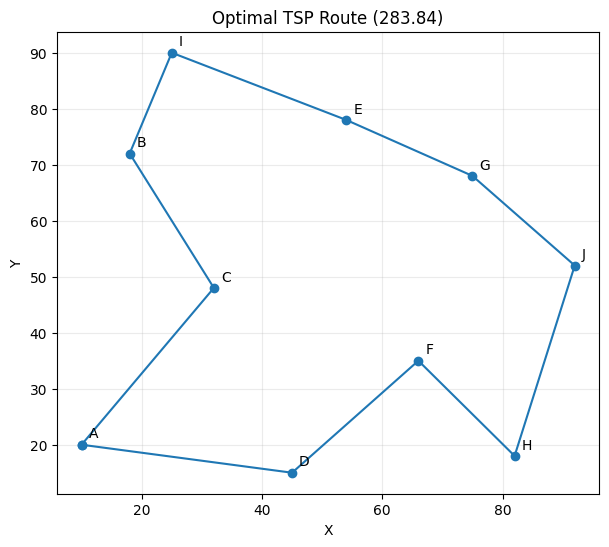

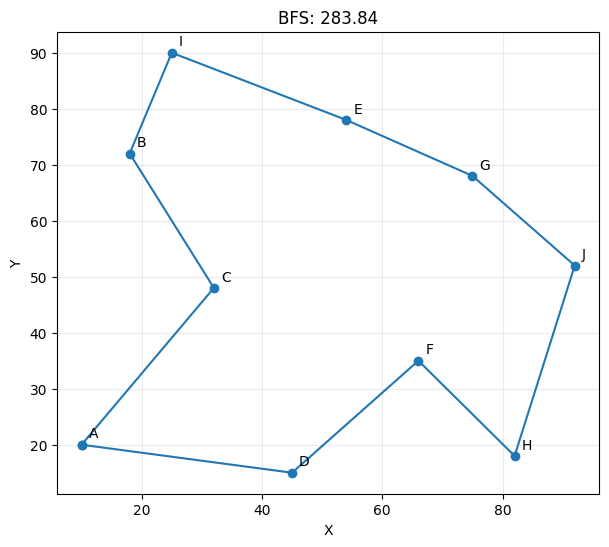

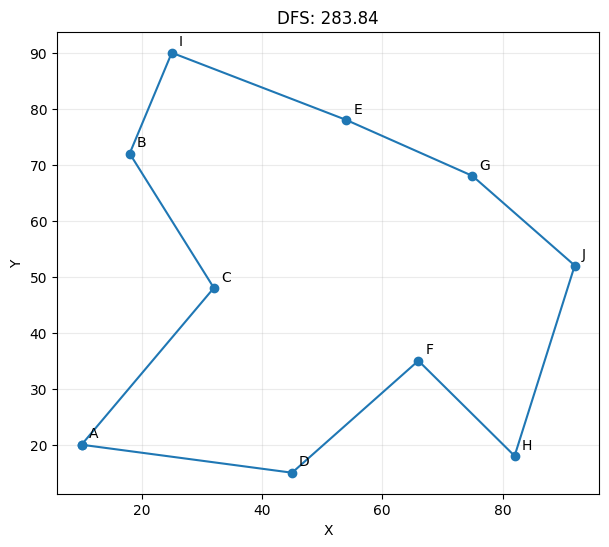

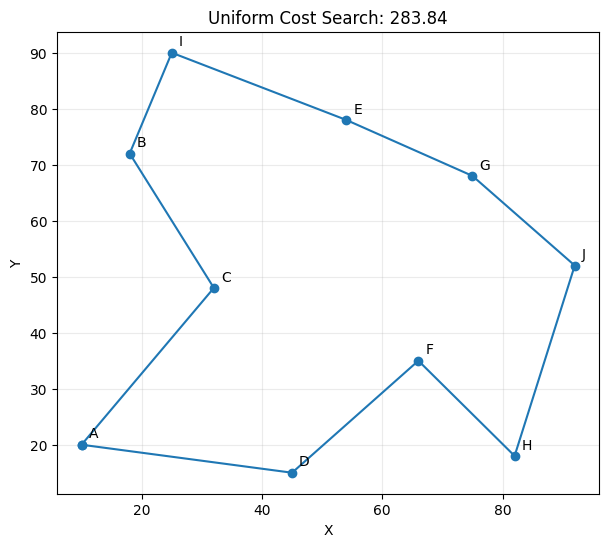

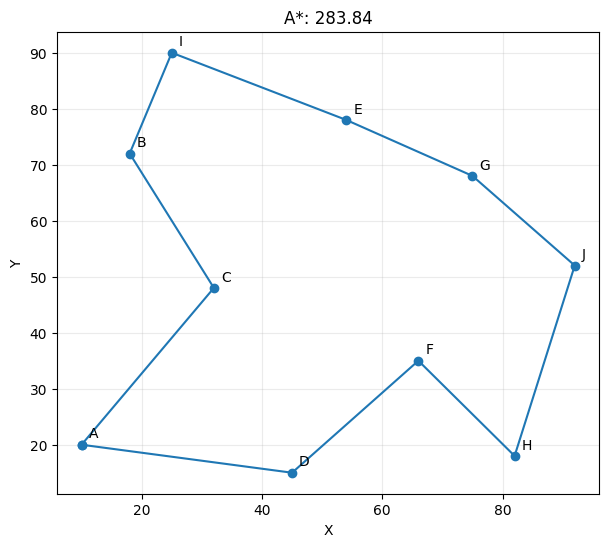

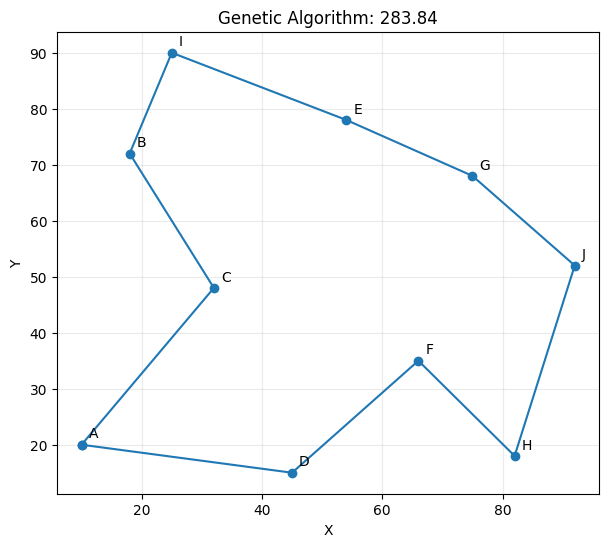

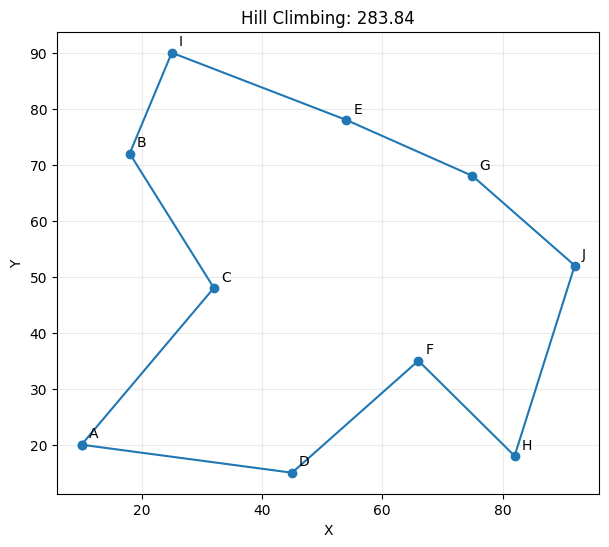

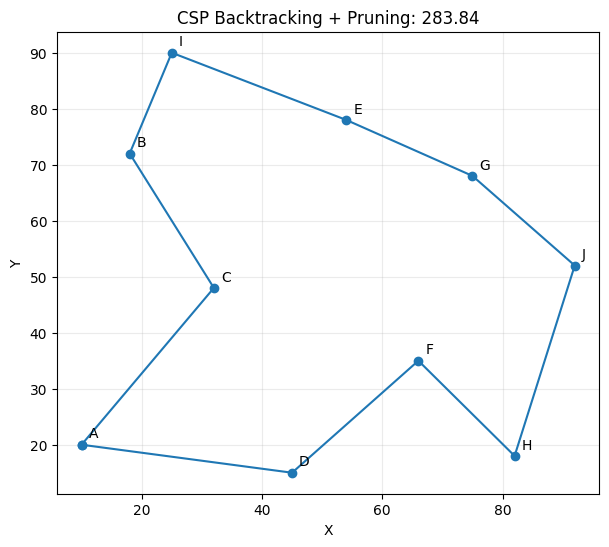

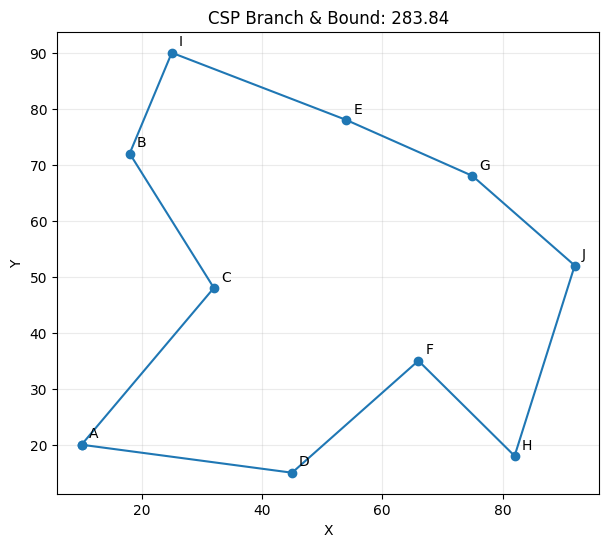

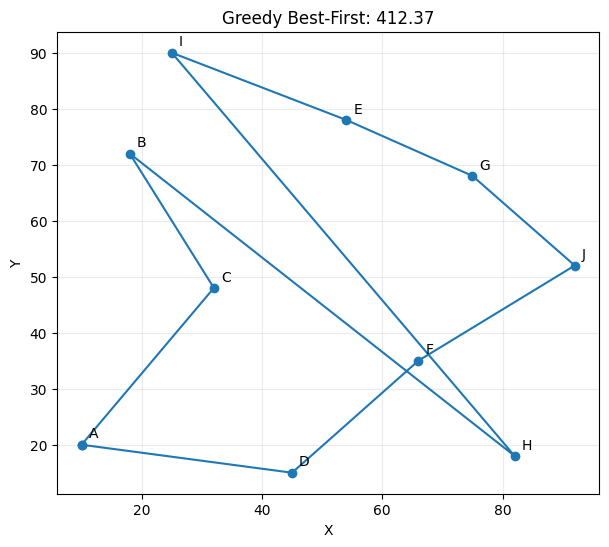

In [ ]:
def plot_route(route, title):
    xs = [COORDS[CITY_NAMES[i]][0] for i in route + [route[0]]]
    ys = [COORDS[CITY_NAMES[i]][1] for i in route + [route[0]]]
    plt.figure(figsize=(7, 6))
    plt.plot(xs, ys, marker="o")
    for i in route:
        x, y = COORDS[CITY_NAMES[i]]
        plt.annotate(CITY_NAMES[i], (x, y), xytext=(5, 5), textcoords="offset points")
    plt.title(title)
    plt.xlabel("X")
    plt.ylabel("Y")
    plt.grid(alpha=0.25)
    plt.show()

plot_route(opt_route, f"Optimal TSP Route ({opt_cost:.2f})")

for _, row in results_df.iterrows():
    if row["Route"]:
        route = [CITY_NAMES.index(x) for x in row["Route"].split(" -> ")[:-1]]
        plot_route(route, f'{row["Algorithm"]}: {row["Distance"]:.2f}')

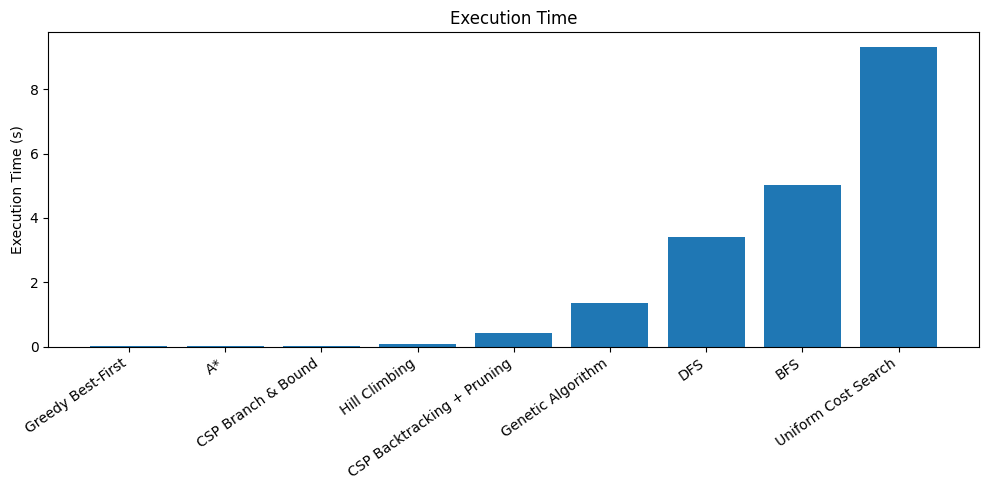

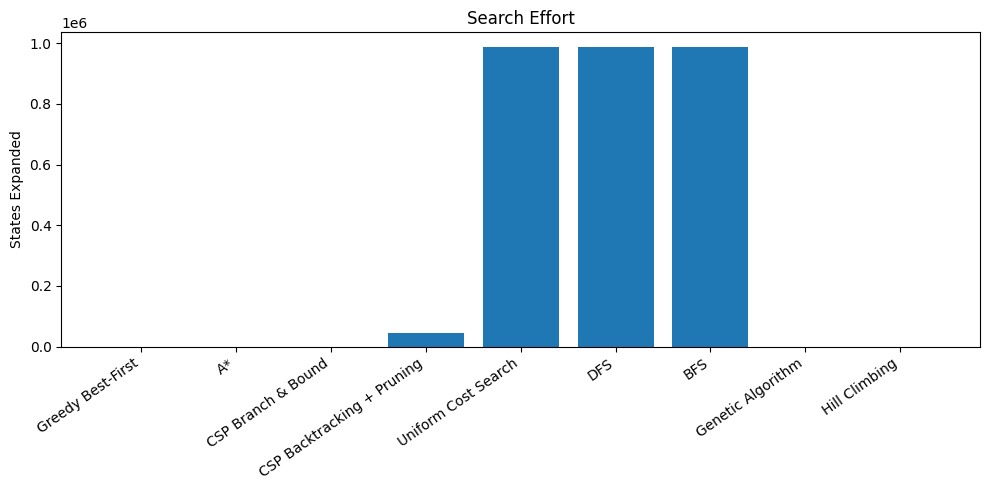

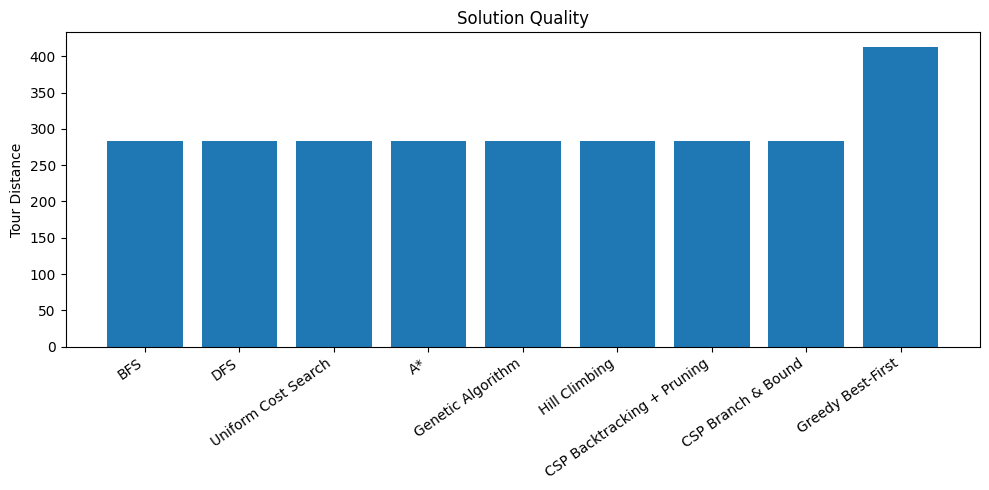

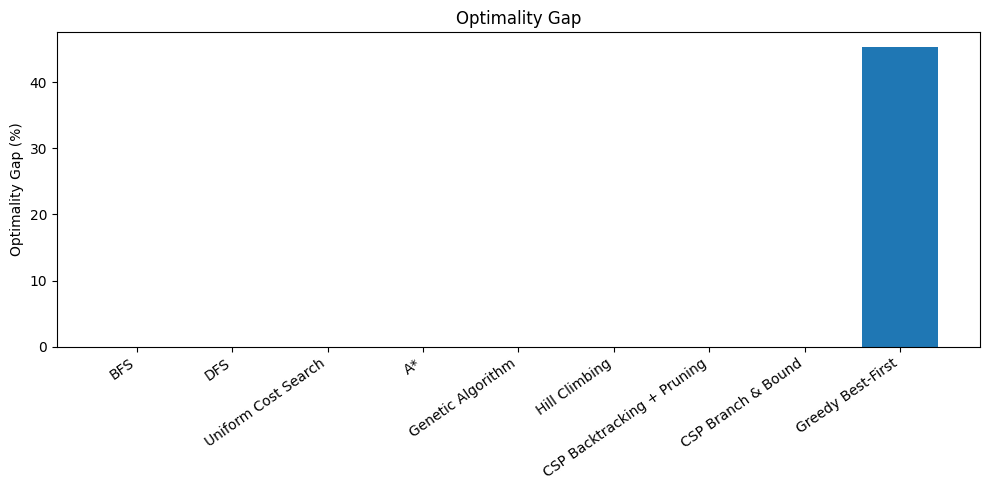

In [ ]:
plot_df = results_df.dropna(subset=["Time (s)"]).sort_values("Time (s)")
plt.figure(figsize=(10, 5))
plt.bar(plot_df["Algorithm"], plot_df["Time (s)"])
plt.xticks(rotation=35, ha="right")
plt.ylabel("Execution Time (s)")
plt.title("Execution Time")
plt.tight_layout()
plt.show()

plot_df = results_df.sort_values("States Expanded", na_position="last")
plt.figure(figsize=(10, 5))
plt.bar(plot_df["Algorithm"], plot_df["States Expanded"].fillna(0))
plt.xticks(rotation=35, ha="right")
plt.ylabel("States Expanded")
plt.title("Search Effort")
plt.tight_layout()
plt.show()

plot_df = results_df.sort_values("Distance")
plt.figure(figsize=(10, 5))
plt.bar(plot_df["Algorithm"], plot_df["Distance"])
plt.xticks(rotation=35, ha="right")
plt.ylabel("Tour Distance")
plt.title("Solution Quality")
plt.tight_layout()
plt.show()

plt.figure(figsize=(10, 5))
plt.bar(plot_df["Algorithm"], plot_df["Optimality Gap (%)"].clip(lower=0))
plt.xticks(rotation=35, ha="right")
plt.ylabel("Optimality Gap (%)")
plt.title("Optimality Gap")
plt.tight_layout()
plt.show()

,Cities,Algorithm,Distance,Time (s),States Expanded
0,6,BFS,208.89,0.000315,326.0
1,6,DFS,208.89,0.000234,326.0
2,6,UCS,208.89,0.000314,326.0
3,6,Greedy,237.84,0.000103,6.0
4,6,A*,208.89,0.000117,6.0
5,6,Hill Climbing,208.89,0.001405,NaN
6,6,Genetic Algorithm,208.89,0.099711,NaN
7,6,CSP B&B,208.89,0.000104,20.0
8,8,BFS,253.19,0.009869,13700.0
9,8,DFS,253.19,0.006447,13700.0


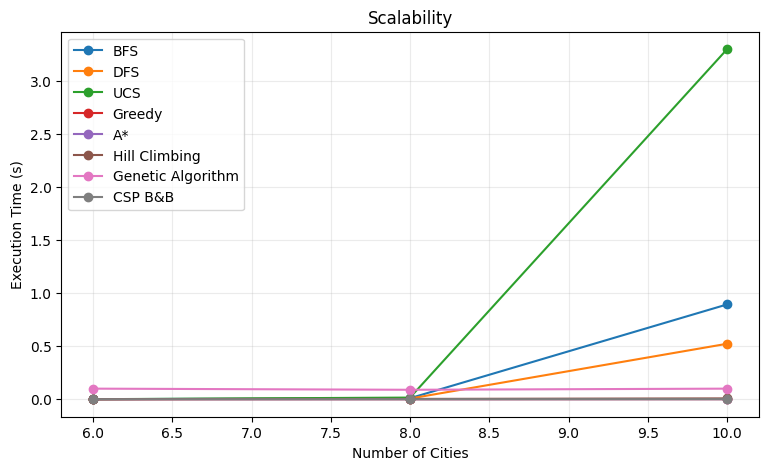

In [ ]:
scalability_sizes = [6, 7, 8]
scalability_rows = []

for n in scalability_sizes:
    sub = CITY_NAMES[:n]
    d = build_distance_matrix(sub)

    for name, fn in [
        ("BFS", lambda: bfs_tsp(d)),
        ("DFS", lambda: dfs_tsp(d)),
        ("UCS", lambda: ucs_tsp(d)),
        ("Greedy", lambda: greedy_tsp(d)),
        ("A*", lambda: astar_tsp(d)),
        ("Hill Climbing", lambda: hill_climbing_tsp(d, restarts=20, max_iter=500)),
        ("Genetic Algorithm", lambda: genetic_algorithm_tsp(d, population_size=60, generations=200)),
        ("CSP B&B", lambda: branch_and_bound_tsp(d)),
    ]:
        t0 = time.perf_counter()
        out = fn()
        elapsed = time.perf_counter() - t0
        if name == "Hill Climbing":
            route, cost, iterations, success = out
            expanded = np.nan
        elif name == "Genetic Algorithm":
            route, cost, generations, history = out
            expanded = np.nan
        else:
            route, cost, expanded = out
        scalability_rows.append([n, name, round(cost, 2), elapsed, expanded])

scalability_df = pd.DataFrame(
    scalability_rows,
    columns=["Cities", "Algorithm", "Distance", "Time (s)", "States Expanded"]
)
display(scalability_df)

plt.figure(figsize=(9, 5))
for name in scalability_df["Algorithm"].unique():
    tmp = scalability_df[scalability_df["Algorithm"] == name]
    plt.plot(tmp["Cities"], tmp["Time (s)"], marker="o", label=name)
plt.xlabel("Number of Cities")
plt.ylabel("Execution Time (s)")
plt.title("Scalability")
plt.legend()
plt.grid(alpha=0.25)
plt.show()

In [ ]:
comparison = results_df[[
    "Algorithm", "Distance", "Optimality Gap (%)",
    "Time (s)", "Peak Memory (MB)", "States Expanded",
    "Iterations", "Generations", "Success / Restarts"
]].copy()

display(comparison)

print("Best exact distance:", round(opt_cost, 2))
print("Best route:", route_text(opt_route))
print()
print("Analysis points:")
print("1. BFS and DFS enumerate many partial tours and do not use a cost heuristic.")
print("2. UCS orders partial tours by accumulated path cost.")
print("3. Greedy uses only the heuristic, while A* combines path cost and heuristic.")
print("4. Hill Climbing trades global guarantees for speed and can depend on initialization.")
print("5. Genetic Algorithm searches a population and is stochastic.")
print("6. CSP methods use constraints; Branch & Bound adds cost-based pruning.")

,Algorithm,Distance,Optimality Gap (%),Time (s),Peak Memory (MB),States Expanded,Iterations,Generations,Success / Restarts
0,BFS,283.84,0.000,5.040561,75.787,986410.0,NaN,NaN,NaN
1,DFS,283.84,0.000,3.411640,0.003,986410.0,NaN,NaN,NaN
2,Uniform Cost Search,283.84,0.000,9.307614,55.848,986410.0,NaN,NaN,NaN
3,A*,283.84,0.000,0.005053,0.008,16.0,NaN,NaN,NaN
4,Genetic Algorithm,283.84,0.000,1.349397,0.064,NaN,NaN,300.0,NaN
5,Hill Climbing,283.84,0.000,0.084207,0.002,NaN,177.0,NaN,30.0
6,CSP Backtracking + Pruning,283.84,0.000,0.432565,0.007,43197.0,NaN,NaN,NaN
7,CSP Branch & Bound,283.84,0.000,0.005143,0.008,79.0,NaN,NaN,NaN
8,Greedy Best-First,412.37,45.283,0.003547,0.009,10.0,NaN,NaN,NaN


Best exact distance: 283.84
Best route: A -> C -> B -> I -> E -> G -> J -> H -> F -> D -> A

Analysis points:
1. BFS and DFS enumerate many partial tours and do not use a cost heuristic.
2. UCS orders partial tours by accumulated path cost.
3. Greedy uses only the heuristic, while A* combines path cost and heuristic.
4. Hill Climbing trades global guarantees for speed and can depend on initialization.
5. Genetic Algorithm searches a population and is stochastic.
6. CSP methods use constraints; Branch & Bound adds cost-based pruning.
